In [1]:
import mne
import torch

from pathlib import Path
from tqdm import tqdm

import numpy as np
import matplotlib.pyplot as plt

import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torch.utils.data import DataLoader

from sklearn.model_selection import train_test_split

In [2]:
def prepare_eeg_data(epochs: mne.Epochs, label_key: str = 'condition'):
    """
    Extracts data from MNE Epochs, normalizes signals, and returns train/val/test splits.
    
    Args:
        epochs: mne.Epochs object with 14 channels.
        label_key: metadata column name or event dictionary key for target digits (0-9).
    """
    # 1. Extract data array: shape (n_trials, 14, n_times)
    X = epochs.get_data(copy=True)  # in Volts (e.g., 1e-6)
    
    # Scale to microvolts or standardize per trial across time to avoid numerical issues
    # Z-score per channel per trial:
    mean = np.mean(X, axis=-1, keepdims=True)
    std = np.std(X, axis=-1, keepdims=True) + 1e-8
    X = (X - mean) / std

    # 2. Transpose to (n_trials, n_times, n_channels) for PyTorch RNN (batch, seq_len, features)
    X = np.transpose(X, (0, 2, 1)).astype(np.float32)

    # 3. Extract labels (assuming integer targets 0 to 9)
    if epochs.metadata is not None and label_key in epochs.metadata:
        y = epochs.metadata[label_key].values.astype(np.int64)
    else:
        # If stored in events array (3rd column)
        y = epochs.events[:, 2].astype(np.int64)
        # Remap event IDs to 0-9 if necessary
        unique_labels = np.unique(y)
        label_map = {lbl: idx for idx, lbl in enumerate(sorted(unique_labels))}
        y = np.array([label_map[val] for val in y], dtype=np.int64)

    # 4. Stratified Split: 80% Train, 10% Val, 10% Test
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=42
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
    )

    return (X_train, y_train), (X_val, y_val), (X_test, y_test)

In [3]:
class EEGDataset(Dataset):
    """
    Custom Dataset to wrap EEG feature matrices (X) and integer labels (y).
    Expects:
      - X: np.ndarray of shape (n_trials, seq_len, n_channels)
      - y: np.ndarray of shape (n_trials,)
    """
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).long()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def get_dataloaders(splits, batch_size=64):
    """
    Creates DataLoader instances for train, validation, and test splits.
    """
    (X_tr, y_tr), (X_va, y_va), (X_te, y_te) = splits
    
    train_loader = DataLoader(
        EEGDataset(X_tr, y_tr), 
        batch_size=batch_size, 
        shuffle=True, 
        drop_last=False
    )
    val_loader = DataLoader(
        EEGDataset(X_va, y_va), 
        batch_size=batch_size, 
        shuffle=False
    )
    test_loader = DataLoader(
        EEGDataset(X_te, y_te), 
        batch_size=batch_size, 
        shuffle=False
    )
    
    return train_loader, val_loader, test_loader

In [4]:
class EEGRecurrentDecoder(nn.Module):
    def __init__(
        self,
        in_channels: int = 14,
        hidden_dim: int = 28,
        num_layers: int = 1,
        num_classes: int = 11,
        dropout: float = 0.3
    ):
        super().__init__()
        
        # 1. Temporal Feature Extractor (reduces sequence length & extracts spectral transients)
        # Input: (batch, channels, seq_len)
        self.feature_extractor = nn.Sequential(
            nn.Conv1d(in_channels=in_channels, out_channels=32, kernel_size=15, stride=2, padding=7),
            nn.BatchNorm1d(32),
            nn.ELU(),
            nn.Dropout(dropout)
        )
        
        # 2. Recurrent Sequential Processor (Bi-GRU)
        # Input: (batch, seq_len, 32)
        self.rnn = nn.GRU(
            input_size=32,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        
        # 3. Dense Classifier Head
        # Bidirectional produces 2 * hidden_dim
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # x is (batch_size, seq_len, 14)
        # Permute for Conv1D: (batch_size, 14, seq_len)
        x = x.permute(0, 2, 1)
        x = self.feature_extractor(x)
        
        # Permute back for GRU: (batch_size, seq_len_subsampled, 32)
        x = x.permute(0, 2, 1)
        
        # Recurrent pass
        rnn_out, _ = self.rnn(x)  # (batch_size, seq_len_subsampled, hidden_dim * 2)
        
        # Mean pooling across the time dimension to aggregate temporal evidence
        pooled = torch.mean(rnn_out, dim=1)  # (batch_size, hidden_dim * 2)
        
        # Logits
        logits = self.classifier(pooled)
        return logits

In [5]:
def train_epoch(model, loader, criterion, optimizer, device, num_classes: int = 11):
    model.train()

    total_loss, correct, total = 0.0, 0, 0
    class_correct = np.zeros(num_classes, dtype=np.int64)
    class_total = np.zeros(num_classes, dtype=np.int64)

    pbar = tqdm(total=len(loader)*64, desc=f'Running epoch:') #make 64 bsize somehow TODO
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        
        # Gradient clipping prevents exploding gradients in RNNs
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()
        
        total_loss += loss.item() * len(y_batch)
        preds = outputs.argmax(dim=1)

        # Accumulate correct predictions and counts per class
        for label in range(num_classes):
            mask = (y_batch == label)
            class_total[label] += mask.sum().item()
            class_correct[label] += (preds[mask] == label).sum().item()

        correct += (preds == y_batch).sum().item()
        total += len(y_batch)
        pbar.update(len(y_batch))
    pbar.close()

    # Avoid zero-division if a class has no samples in the split
    per_class_acc = np.divide(
        class_correct,
        class_total,
        out=np.zeros(num_classes, dtype=float),
        where=class_total != 0
    )
        
    return total_loss / total, correct / total, per_class_acc, class_total

@torch.no_grad()
def evaluate(model, loader, criterion, device, num_classes: int = 11):
    """
    Evaluates the model over a DataLoader and computes overall and per-class accuracies.

    Args:
        model: PyTorch nn.Module.
        loader: DataLoader for evaluation.
        criterion: Loss function (e.g., nn.CrossEntropyLoss()).
        device: torch.device ('cuda' or 'cpu').
        num_classes: Total number of classes (default: 11 for MNIST digits 0-9 and -1 for no-number).

    Returns:
        dict: {
            'loss': float,
            'overall_acc': float,
            'per_class_acc': np.ndarray of shape (num_classes,),
            'class_counts': np.ndarray of shape (num_classes,)
        }
    """
    model.eval()
    
    class_correct = np.zeros(num_classes, dtype=np.int64)
    class_total = np.zeros(num_classes, dtype=np.int64)
    total_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        total_loss += loss.item() * len(y_batch)
        total_samples += len(y_batch)

        preds = outputs.argmax(dim=1)

        # Accumulate correct predictions and counts per class
        for label in range(num_classes):
            mask = (y_batch == label)
            class_total[label] += mask.sum().item()
            class_correct[label] += (preds[mask] == label).sum().item()

    # Calculate overall metrics
    avg_loss = total_loss / total_samples if total_samples > 0 else 0.0
    overall_acc = class_correct.sum() / class_total.sum() if class_total.sum() > 0 else 0.0

    # Avoid zero-division if a class has no samples in the split
    per_class_acc = np.divide(
        class_correct,
        class_total,
        out=np.zeros(num_classes, dtype=float),
        where=class_total != 0
    )

    return avg_loss, overall_acc, per_class_acc, class_total

In [ ]:
def run_pipeline(epochs: mne.Epochs, num_epochs=30, lr=1e-3, batch_size=64):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Training on device: {device}")

    # 1. Process dataset
    splits = prepare_eeg_data(epochs)
    train_loader, val_loader, test_loader = get_dataloaders(splits, batch_size=batch_size)

    # 2. Initialize Model
    model = EEGRecurrentDecoder(
        in_channels=14,
        hidden_dim=128,
        num_layers=2,
        num_classes=11,
        dropout=0.3
    ).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=5, factor=0.5)

    #loss and accuracy aggregator
    loss_hist, acc_hist = np.zeros((num_epochs,3), dtype=np.float64), np.zeros((num_epochs,3), dtype=np.float64)
    perc_hist, ctot_hist = np.zeros((num_epochs, 3, 11), dtype=np.float64), np.zeros((num_epochs, 3, 11), dtype=np.int64)

    # 3. Training Loop with Model Checkpointing
    best_val_acc = 0.0
    for epoch in range(1, num_epochs + 1):
        train_loss, train_acc, train_perc, train_ctot = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, val_perc, val_ctot = evaluate(model, val_loader, criterion, device)
        test_loss, test_acc, test_perc, test_ctot = evaluate(model, test_loader, criterion, device)
        scheduler.step(val_acc)

        loss_hist[epoch-1] = np.stack([train_loss, val_loss, test_loss], axis=0)
        acc_hist[epoch-1] = np.stack([train_acc, val_acc, test_acc], axis=0)
        perc_hist[epoch-1] = np.stack([train_perc, val_perc, test_perc], axis=0)
        ctot_hist[epoch-1] = np.stack([train_ctot, val_ctot, test_ctot], axis=0)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            Path('./weights/').mkdir(exist_ok=True)
            torch.save(model.state_dict(), './weights/best_eeg_decoder.pt')

        print(
            f"Epoch [{epoch:02d}/{num_epochs}] | "
            f"Train Loss: {train_loss:.4f}, Acc: {train_acc*100:.2f}% | "
            f"Val Loss: {val_loss:.4f}, Acc: {val_acc*100:.2f}% | "
            f"Test Loss: {test_loss:.4f}, Acc: {test_acc*100:.2f}%"
            )

    # 4. Final Evaluation on Test Set
    model.load_state_dict(torch.load('./weights/best_eeg_decoder.pt'))
    test_loss, test_acc, _, _ = evaluate(model, test_loader, criterion, device)
    print(f"\nFinal Test Performance -> Loss: {test_loss:.4f}, Accuracy: {test_acc*100:.2f}%")

    return loss_hist, acc_hist, perc_hist, ctot_hist

In [7]:
loss_hist, acc_hist, perc_hist, ctot_hist = run_pipeline(mne.read_epochs('../EEG/data/MNIST_small_epochs.fif'))

Reading /workspaces/NeuralDataAnalysisTools2026/models/../EEG/data/MNIST_small_epochs.fif ...


/tmp/ipykernel_11444/3889871928.py:1: RuntimeWarning: This filename (../EEG/data/MNIST_small_epochs.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  loss_hist, acc_hist, perc_hist, ctot_hist = run_pipeline(mne.read_epochs('../EEG/data/MNIST_small_epochs.fif'))


    Found the data of interest:
        t =    -203.12 ...     500.00 ms
        0 CTF compensation matrices available
Not setting metadata
58520 matching events found
No baseline correction applied
0 projection items activated
Training on device: cuda


Running epoch:: 100%|█████████▉| 46816/46848 [00:06<00:00, 6706.63it/s]


Epoch [01/30] | Train Loss: 2.3212, Acc: 9.80% | Val Loss: 2.3083, Acc: 10.48% | Test Loss: 2.3088, Acc: 10.42%


...

Epoch [28/30] | Train Loss: 2.0682, Acc: 23.46% | Val Loss: 2.4012, Acc: 13.48% | Test Loss: 2.4072, Acc: 13.52%


Running epoch:: 100%|█████████▉| 46816/46848 [00:05<00:00, 8668.30it/s]


Epoch [29/30] | Train Loss: 2.0562, Acc: 24.06% | Val Loss: 2.3953, Acc: 13.67% | Test Loss: 2.4030, Acc: 13.47%


Running epoch:: 100%|█████████▉| 46816/46848 [00:05<00:00, 8981.54it/s]


Epoch [30/30] | Train Loss: 2.0203, Acc: 25.28% | Val Loss: 2.4315, Acc: 13.04% | Test Loss: 2.4436, Acc: 13.06%

Final Test Performance -> Loss: 2.2741, Accuracy: 14.64%


In [8]:
def plot_training_metrics(loss_hist: np.ndarray, acc_hist: np.ndarray):
    """
    Plots training, validation, and test curves in 'bmh' style.
    
    Args:
        loss_hist: np.ndarray of shape (epochs, 3) -> columns: [train, val, test]
        acc_hist:  np.ndarray of shape (epochs, 3) -> columns: [train, val, test]
    """
    plt.style.use('bmh')

    num_epochs = loss_hist.shape[0]
    epochs = np.arange(1, num_epochs + 1)

    # Convert accuracy to percentage if provided in decimal [0, 1] range
    acc_data = acc_hist * 100 if np.max(acc_hist) <= 1.0 else acc_hist.copy()

    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

    # --- Subplot 1: Loss ---
    ax_loss.plot(epochs, loss_hist[:, 0], label='Train Loss', color='#348ABD', linewidth=2)
    ax_loss.plot(epochs, loss_hist[:, 1], label='Val Loss', color='#E24A33', linewidth=2)
    ax_loss.plot(epochs, loss_hist[:, 2], label='Test Loss', color='#8EBA63', linewidth=2, linestyle='--')
    
    ax_loss.set_title('Cross-Entropy Loss Across Epochs', fontsize=13, fontweight='bold', pad=10)
    ax_loss.set_xlabel('Epoch', fontsize=11)
    ax_loss.set_ylabel('Loss', fontsize=11)
    ax_loss.legend(frameon=True, facecolor='white', framealpha=0.9)

    # --- Subplot 2: Accuracy ---
    ax_acc.plot(epochs, acc_data[:, 0], label='Train Accuracy', color='#348ABD', linewidth=2)
    ax_acc.plot(epochs, acc_data[:, 1], label='Val Accuracy', color='#E24A33', linewidth=2)
    ax_acc.plot(epochs, acc_data[:, 2], label='Test Accuracy', color='#8EBA63', linewidth=2, linestyle='--')
    
    ax_acc.set_title('Classification Accuracy Across Epochs', fontsize=13, fontweight='bold', pad=10)
    ax_acc.set_xlabel('Epoch', fontsize=11)
    ax_acc.set_ylabel('Accuracy (%)', fontsize=11)
    ax_acc.legend(frameon=True, facecolor='white', framealpha=0.9)

    plt.tight_layout()
    
    Path('./plots/').mkdir(exist_ok=True)
    plt.savefig('./plots/training_metricss.png')

    plt.show()

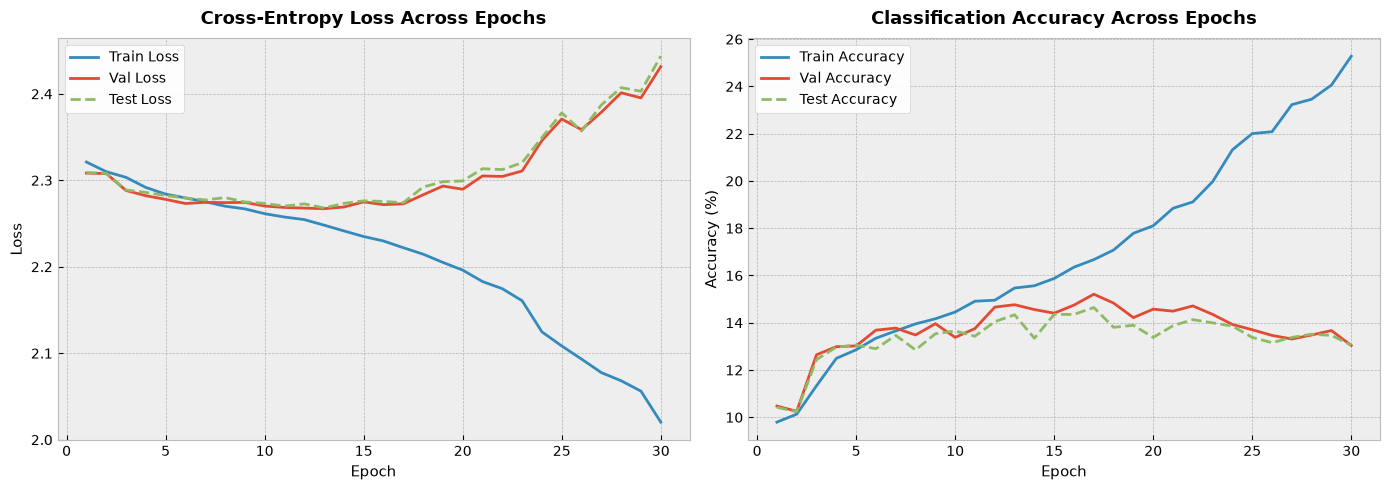

In [9]:
plot_training_metrics(loss_hist, acc_hist)

In [10]:
def plot_label_wise_analysis(
    acc_hist: np.ndarray, 
    val_acc: np.ndarray,
    class_counts: np.ndarray = None, 
    class_names: list = None,
):
    """
    Plots comprehensive per-class metrics: final snapshot and historical trajectory.

    Args:
        acc_hist: np.ndarray of shape (epochs, 3, labels)
                  Ordering along axis 1: 0 -> Train, 1 -> Val, 2 -> Test.
        class_counts: Optional np.ndarray of shape (labels,) showing sample support.
        class_names: Optional list of str for custom class tick labels.
    """
    plt.style.use('bmh')

    best_epoch = np.argmax(val_acc,axis=0) #we find the best epoch validation-accuracy-wise

    n_epochs, n_splits, n_labels = acc_hist.shape
    if class_names is None:
        class_names = [f"Digit {i}" for i in range(n_labels)]
    
    # Scale to percentage [0, 100] if input is in [0, 1] range
    acc_data = acc_hist * 100 if np.max(acc_hist) <= 1.0 else acc_hist.copy()

    fig = plt.figure(figsize=(16, 10), dpi=100)
    gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.1], hspace=0.35, wspace=0.25)

    ax_bars = fig.add_subplot(gs[0, 0])
    ax_counts = fig.add_subplot(gs[0, 1])
    ax_traj = fig.add_subplot(gs[1, 0])
    ax_heat = fig.add_subplot(gs[1, 1])

    x = np.arange(n_labels)
    epochs_axis = np.arange(1, n_epochs + 1)

    # -------------------------------------------------------------
    # 1. Final Epoch Accuracy by Split (Grouped Bar Chart)
    # -------------------------------------------------------------
    bar_width = 0.26
    split_meta = [
        ('Train', '#348ABD', -bar_width),
        ('Val',   '#E24A33', 0.0),
        ('Test',  '#8EBA63', bar_width)
    ]

    for s_idx, (s_name, color, offset) in enumerate(split_meta):
        ax_bars.bar(
            x + offset, 
            acc_data[best_epoch, s_idx, :], 
            bar_width, 
            label=s_name, 
            color=color, 
            alpha=0.85
        )

    # Theoretical chance level
    chance = 100.0 / n_labels
    ax_bars.axhline(chance, color='gray', linestyle=':', linewidth=1.5, label=f'Chance ({chance:.1f}%)')
    ax_bars.set_title(f'Best Epoch (Epoch {best_epoch}) Accuracy per Class', fontsize=12, fontweight='bold')
    ax_bars.set_xlabel('Class', fontsize=10)
    ax_bars.set_ylabel('Accuracy (%)', fontsize=10)
    ax_bars.set_xticks(x)
    ax_bars.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
    ax_bars.set_ylim(0, 105)
    ax_bars.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9)

    # -------------------------------------------------------------
    # 2. Final Test Accuracy vs. Sample Counts
    # -------------------------------------------------------------
    if class_counts is not None:
        ax_support = ax_counts.twinx()
        ax_counts.bar(x, class_counts, color='#988ED5', alpha=0.55, width=0.45, label='Sample Count')
        ax_support.plot(x, acc_data[best_epoch, 2, :], color='#E24A33', marker='o', linewidth=2.0, label='Test Accuracy')
        
        ax_counts.set_title('Test Accuracy vs. Class Sample Support (Best)', fontsize=12, fontweight='bold')
        ax_counts.set_xlabel('Class', fontsize=10)
        ax_counts.set_ylabel('Number of Samples', fontsize=10)
        ax_support.set_ylabel('Test Accuracy (%)', fontsize=10)
        ax_support.set_ylim(0, 105)
        ax_counts.set_xticks(x)
        ax_counts.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
        ax_counts.grid(False)  # Avoid misaligned overlaid grids

        lines1, labels1 = ax_counts.get_legend_handles_labels()
        lines2, labels2 = ax_support.get_legend_handles_labels()
        ax_counts.legend(lines1 + lines2, labels1 + labels2, frameon=True, facecolor='white', framealpha=0.9, fontsize=9)
    else:
        # Fallback: Split matrix heatmap if counts are not passed
        heatmap_matrix = acc_data[-1].T  # (n_labels, 3)
        cax = ax_counts.imshow(heatmap_matrix, cmap='YlGnBu', aspect='auto', vmin=0, vmax=100)
        fig.colorbar(cax, ax=ax_counts, fraction=0.046, pad=0.04, label='Accuracy (%)')
        ax_counts.set_title('Final Accuracy Matrix Across Splits', fontsize=12, fontweight='bold')
        ax_counts.set_xticks([0, 1, 2])
        ax_counts.set_xticklabels(['Train', 'Val', 'Test'], fontsize=9)
        ax_counts.set_yticks(x)
        ax_counts.set_yticklabels(class_names, fontsize=9)

    # -------------------------------------------------------------
    # 3. Test Accuracy Trajectory per Class Over Epochs
    # -------------------------------------------------------------
    cmap = plt.get_cmap('tab10', n_labels)
    for c in range(n_labels):
        ax_traj.plot(epochs_axis, acc_data[:, 2, c], label=class_names[c], linewidth=1.8, color=cmap(c))
    
    ax_traj.set_title('Test Accuracy Trajectory per Class', fontsize=12, fontweight='bold')
    ax_traj.set_xlabel('Epoch', fontsize=10)
    ax_traj.set_xticks(range(1,len(val_acc)))
    ax_traj.set_ylabel('Accuracy (%)', fontsize=10)
    ax_traj.set_ylim(0, 105)
    ax_traj.legend(loc='lower right', ncol=2, frameon=True, facecolor='white', framealpha=0.85, fontsize=8)

    # -------------------------------------------------------------
    # 4. Validation Accuracy Evolution (Epoch × Class Heatmap)
    # -------------------------------------------------------------
    # Shape: (labels, epochs)
    heat_im = ax_heat.imshow(
        acc_data[:, 1, :].T, 
        aspect='auto', 
        cmap='viridis', 
        origin='lower', 
        extent=[1, n_epochs, -0.5, n_labels - 0.5]
    )
    cbar = fig.colorbar(heat_im, ax=ax_heat, fraction=0.046, pad=0.04)
    cbar.set_label('Val Acc (%)', fontsize=9)
    
    ax_heat.set_title('Validation Accuracy Heatmap (Epoch × Class)', fontsize=12, fontweight='bold')
    ax_heat.set_xlabel('Epoch', fontsize=10)
    ax_heat.set_xticks(range(1,len(val_acc)))
    ax_heat.set_ylabel('Class', fontsize=10)
    ax_heat.set_yticks(range(n_labels))
    ax_heat.set_yticklabels(class_names, fontsize=9)

    plt.tight_layout()

    Path('./plots/').mkdir(exist_ok=True)
    plt.savefig(f'./plots/labelwise_acc.png')

    plt.show()

/tmp/ipykernel_11444/1528864300.py:135: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


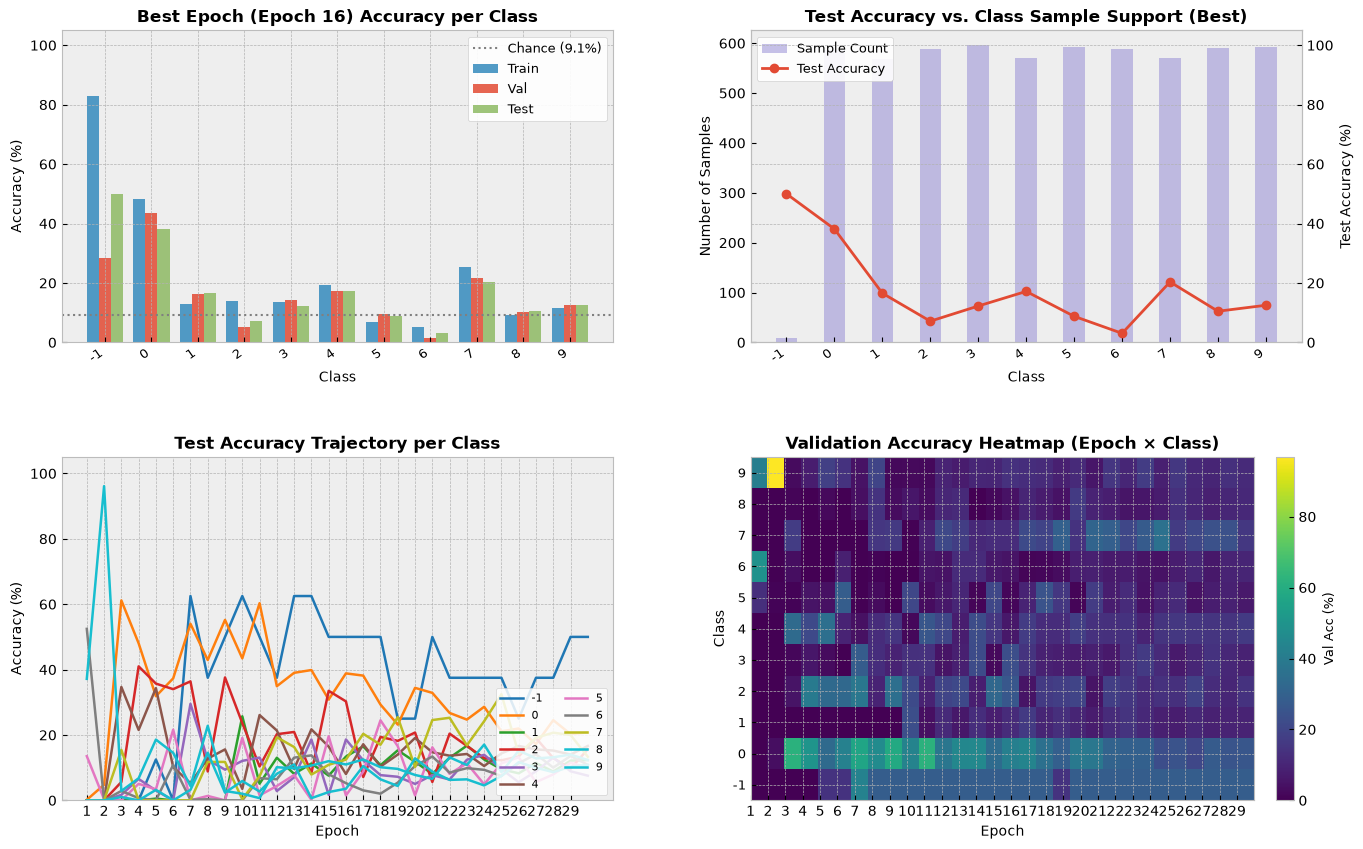

In [11]:
plot_label_wise_analysis(perc_hist, acc_hist[:, 1],ctot_hist[0, 2, :], ['-1', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9'])